# Rilevamento anomalie — Neural Network (PyTorch)
Prerequisito: eseguire prima il notebook della pipeline, che produce il file `.npz`.

La valutazione finale nella cella 10 confronta sempre la rete con una baseline (il solo criterio SNR/salto della pipeline), sceglie la soglia in base ai falsi allarmi al giorno accettati. Questa soglia è comune alla baseline e al risultato della neural network. 
I conteggi dei rilevamenti vengono assegnati per evento, ovvero il segnale rilevato è associato al singolo evento e non alla finestra perché le finestre si sovrappongono (una finestra ogni 7s e sono lunghe 9s) per includere tutto il transiente del fulmine. Questo approccio non causa problemi perché i rilevamenti a meno di 10s uno dall'altro sono abbinati allo stesso evento.
Ci sono tre misure:
1. falsi allarmi al giorno nelle giornate senza fulmini (lì ogni allarme è un errore);
2. recall sui fulmini di catalogo con segnale visibile;
3. rilevamenti extra attorno ai temporali: si concentrano vicino ai fulmini (→ probabili fulmini non in catalogo) o sono distribuiti uniformemente (→ falsi allarmi)?

## 0 · Dipendenze

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import (
    f1_score, precision_score, recall_score, balanced_accuracy_score,
    classification_report, confusion_matrix, average_precision_score,
    roc_auc_score, roc_curve, precision_recall_curve, ConfusionMatrixDisplay,
)

%matplotlib inline

print(f'PyTorch    : {torch.__version__}')
print(f'Dispositivo: {"cuda" if torch.cuda.is_available() else "cpu"}')

PyTorch    : 2.2.2
Dispositivo: cpu


## 1 · Configurazione
`DATASET_FILE` deve essere **lo stesso file** salvato dalla pipeline (`OUTPUT_FILE2`).

In [2]:
BASE_DIR     = Path(r"C:\Programmi manuali\python\ProgrammiPython\CondaPyTorch")
DATASET_FILE = BASE_DIR / "datasets" / "lightning_dataset50km_v2.npz"
MODEL_OUT    = BASE_DIR / "models" / "lightning_cnn.pt"
MODEL_OUT.parent.mkdir(parents=True, exist_ok=True)

BATCH_SIZE   = 32      # quante finestre vede in parallelo
EPOCHS       = 50      # quante volte passa su tutto il train
LR           = 1e-3    # learning rate iniziale
WEIGHT_DECAY = 1e-4    # regolarizzazione L2

#   Come normalizzare le finestre (vedi cella 3):
#   "globale"       → stessa scala per tutto l'anno
#   "rumore_locale" → ogni finestra divisa per il rumore dei 5 minuti precedenti (si ottengono risultati migliori)
NORMALIZZAZIONE = "rumore_locale"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training su: {DEVICE}")

Training su: cpu


## 2 · Caricamento dataset
Il train non contiene negative difficili (salto forte lontano dai temporali), le finestre ambigue non sono mai nel train.

In [3]:
data = np.load(DATASET_FILE)
X_train, c_train = data["X_train"], data["c_train"]
X_val,   c_val   = data["X_val"],   data["c_val"]
X_test,  c_test  = data["X_test"],  data["c_test"]

# Informazioni aggiuntive sul test (per le tre misure della §10)
g_test       = data["g_test"]         # categoria: 1 pos visibile, 3 pos debole, 0 neg sicura,
                                      #            4 neg quieta vicino temporali, 2 ambigua
dt_test      = data["dt_test"]        # s dal fulmine di catalogo più vicino
dayfree_test = data["dayfree_test"]   # True = giorno senza fulmini in catalogo
t_test       = data["t_test"]
NEGATIVE_STRIDE = int(data["negative_stride"])
CENTER_OFFSET   = int(data["center_offset"])
NOMI_CAT = {1: "pos. visibile", 3: "pos. debole", 0: "neg. sicura", 4: "neg. quieta vicino", 2: "ambigua"}

# [NUOVO] rumore locale (presente solo se la pipeline lo ha salvato)
noise_train = noise_val = noise_test = None
if "noise_train" in data.files:
    noise_train, noise_val, noise_test = data["noise_train"], data["noise_val"], data["noise_test"]
elif NORMALIZZAZIONE == "rumore_locale":
    raise ValueError("Il dataset non contiene il rumore locale: riesegui la pipeline aggiornata "
                     "(con REBUILD = False basta qualche secondo).")
print("Test per categoria:", {NOMI_CAT[k]: int((g_test == k).sum()) for k in NOMI_CAT})

for nome, X, c in [("train", X_train, c_train), ("val", X_val, c_val), ("test", X_test, c_test)]:
    print(f"{nome:5s}: {X.shape}  pos={int(c.sum())}  neg={int((1-c).sum())}  "
          f"min={X.min():.1f}  max={X.max():.1f}  NaN={np.isnan(X).sum()}")

Test per categoria: {'pos. visibile': 116, 'pos. debole': 844, 'neg. sicura': 1110503, 'neg. quieta vicino': 419240, 'ambigua': 37377}
train: (1616, 9, 3)  pos=404  neg=1212  min=89.7  max=1049.6  NaN=0
val  : (57510, 9, 3)  pos=58  neg=57452  min=300.8  max=1038.7  NaN=0
test : (1568080, 9, 3)  pos=960  neg=1567120  min=136.2  max=1153.6  NaN=0


## 3 · Pre-elaborazione e normalizzazione
Problema: normalizzando il valore assoluto del campo (media ≈ 344 / 964 / 680 nT, std ≈ 65–90 nT), il segnale tipico di un fulmine è ~0.04 nT, cioè ~1/2000 della std: dopo la normalizzazione era invisibile. La rete così impara invece il livello di base, che dipende da stagione e ora del giorno (correlati con i temporali) → buon F1 in train, nullo sul test.

F1: L'F1 è la media armonica di precision (frazione di allarmi che sono fulmini veri) e recall (frazione di fulmini veri trovati): F1 = 2·P·R/(P+R). Vale tra 0 e 1 ed è alto solo se entrambe sono alte, perché la media armonica penalizza lo squilibrio tra le due. Dipende dalla soglia di decisione e, con eventi molto rari come i fulmini visibili (circa 1 su 13 000 finestre), resta basso anche per un buon rilevatore, perché pochi falsi allarmi bastano a ridurre molto la precision. Per questo nel progetto l'F1 è riportato solo come informazione; il checkpoint è scelto con l'AUC-PR e il punto di lavoro finale è definito in falsi allarmi al giorno.

Soluzione:
1. si toglie la baseline di ogni finestra (mediana nel tempo, per canale);
    Dopo la rimozione della baseline, le variazioni sono molto piccole (rumore tipico di qualche centesimo di nT) e coprono un intervallo molto ampio (da circa 0.02 a 10 nT). 

2) si dividono per una scala robusta, la MAD (mediana dei valori assoluti × 1.4826), calcolata per ciascuna componente solo sul train ed applicata identica a validation e test. Rispetto alla deviazione standard, la MAD non è influenzata dai pochi valori estremi (fulmini forti, glitch). Dopo questo passo il rumore tipico vale circa 1. Con l'opzione "rumore_locale" si divide invece per il rumore dei 5 minuti precedenti la finestra.

3) si applica arcsinh, che lascia quasi invariati i valori piccoli e comprime in modo 'logaritmico' quelli grandi. Così i rari eventi molto intensi non dominano l'addestramento. A differenza del logaritmo, arcsinh è definita anche per valori negativi e nulli e conserva il segno della variazione.

In [4]:
def detrend(X):
    return X - np.median(X, axis=1, keepdims=True)          # (N, T, 3)

X_train_d, X_val_d, X_test_d = detrend(X_train), detrend(X_val), detrend(X_test)

# scala robusta per canale, solo sul train → niente data leakage
scale = 1.4826 * np.median(np.abs(X_train_d), axis=(0, 1), keepdims=True) + 1e-6

if NORMALIZZAZIONE == "globale":
    def preprocess(Xd, noise=None):
        return np.arcsinh(Xd / scale).astype(np.float32)
    noise_floor = np.nan
elif NORMALIZZAZIONE == "rumore_locale":
    # pavimento: evita divisioni per un rumore quasi nullo (5° percentile del train)
    noise_floor = float(np.nanpercentile(noise_train, 5))
    def preprocess(Xd, noise):
        n = np.maximum(np.nan_to_num(noise, nan=noise_floor), noise_floor)
        return np.arcsinh(Xd / n[:, None, None]).astype(np.float32)
else:
    raise ValueError("NORMALIZZAZIONE deve essere 'globale' o 'rumore_locale'")

X_train_n = preprocess(X_train_d, noise_train)
X_val_n   = preprocess(X_val_d,   noise_val)
X_test_n  = preprocess(X_test_d,  noise_test)
np.savez(MODEL_OUT.with_suffix(".norm.npz"), scale=scale, mode=NORMALIZZAZIONE, noise_floor=noise_floor)
print(f"Normalizzazione: {NORMALIZZAZIONE}")
print("scala per canale (nT), solo globale:", scale.squeeze())
if NORMALIZZAZIONE == "rumore_locale":
    print(f"rumore locale: mediana train = {np.nanmedian(noise_train):.4f} nT/s, pavimento = {noise_floor:.4f}")

Normalizzazione: rumore_locale
scala per canale (nT), solo globale: [0.03705695 0.03112981 0.01782767]
rumore locale: mediana train = 0.0160 nT/s, pavimento = 0.0095


## 4 · Dataset e DataLoader PyTorch

In [5]:
class MagDataset(Dataset):
    """Wrapper PyTorch per le finestre magnetometriche."""
    def __init__(self, X, y):
        # Conv1d vuole (batch, canali, tempo) → trasponiamo da (N, T, C)
        self.X = torch.tensor(X, dtype=torch.float32).permute(0, 2, 1)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(MagDataset(X_train_n, c_train), batch_size=BATCH_SIZE, shuffle=True)
# in valutazione non servono batch piccoli: 4096 rende val/test molto più veloci
val_loader   = DataLoader(MagDataset(X_val_n,  c_val),  batch_size=4096, shuffle=False)
test_loader  = DataLoader(MagDataset(X_test_n, c_test), batch_size=4096, shuffle=False)

print(f"Batch train : {len(train_loader)} × {BATCH_SIZE}")
print(f"Batch val   : {len(val_loader)} × 4096")
print(f"Batch test  : {len(test_loader)} × 4096")

Batch train : 51 × 32
Batch val   : 15 × 4096
Batch test  : 383 × 4096


## 5 · Architettura della rete

| # | Strato | Operazione | Forma dell'uscita |
|:-:|---|---|---|
| – | **Ingresso** | finestra pre-elaborata (3 componenti × 9 s) | (B, 3, 9) |
| 1 | **ConvBlock 1** | Conv1d 3→16 (kernel 3) + BatchNorm + ReLU | (B, 16, 9) |
| 2 | **ConvBlock 2** | Conv1d 16→32 (kernel 3) + BatchNorm + ReLU | (B, 32, 9) |
| 3 | **Global Average Pooling** | media nel tempo di ogni filtro | (B, 32) |
| 4 | **Linear** | 32→64 + ReLU + Dropout 30% | (B, 64) |
| 5 | **Linear** | 64→16 + ReLU | (B, 16) |
| 6 | **Linear** | 16→1 | (B, 1) = logit |
| – | **Sigmoide** | applicata fuori dalla rete | probabilità di fulmine |

B = numero di finestre nel batch.

Conv1d = Un filtro convoluzionale a 3 secondi, il primo blocco ha 16 filtri che cercano contemporaneamente i pesi per la forma locale delle 3 componenti. <br> Il secondo blocco ha 32 filtri che combinano le risposte dei primi 16 e riconoscono forme più complesse.

BatchNorm = Centra e scala le uscite di ogni filtro usando media e deviazione del batch. Rende l'addestramento più stabile e veloce.

ReLU = Lascia passare i valori positivi e azzera i negativi, è la funzione di attivazione che fornisce la non linearità.

Global Average Pooling = fa la media dei 32 filtri sui 9 secondi per ogni finestra

Linear = ogni uscita è una somma pesata di tutti gli ingressi più una costante (bias)

Dropout = durante l'addestramento la rete spegne a caso il 30% dei neuroni a ogni passo. Così la rete non può affidarsi a pochi neuroni specifici e "memorizzare" gli esempi: è una protezione contro l'overfitting. In valutazione è disattivato.

Logit = valore reale

Sigmoide = 1/(1+e⁻ˣ) trasforma il logit in una probabilità tra 0 e 1.

In [6]:
class ConvBlock(nn.Module):
    """Conv1d + BatchNorm + ReLU."""
    def __init__(self, in_ch, out_ch, kernel=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size=kernel, padding=kernel // 2, bias=False),
            nn.BatchNorm1d(out_ch),
            nn.ReLU(),
        )
    def forward(self, x):
        return self.net(x)


class LightningCNN(nn.Module):
    """
    Input  : (batch, 3, T)  — 3 canali, T campioni temporali
    Output : (batch,)       — logit; sigmoid(logit) = probabilità di fulmine
    """
    def __init__(self, in_channels=3):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(in_channels, 16, kernel=3),
            ConvBlock(16, 32, kernel=3),
        )
        self.gap = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 16), nn.ReLU(),
            nn.Linear(16, 1),
        )
    def forward(self, x):
        return self.classifier(self.gap(self.features(x))).squeeze(1)


model = LightningCNN(in_channels=3).to(DEVICE)
print(model)
print(f"\nParametri addestrabili: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

LightningCNN(
  (features): Sequential(
    (0): ConvBlock(
      (net): Sequential(
        (0): Conv1d(3, 16, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
        (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
      )
    )
    (1): ConvBlock(
      (net): Sequential(
        (0): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
      )
    )
  )
  (gap): AdaptiveAvgPool1d(output_size=1)
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)

Parametri addestrabili: 4,945


## 6 · Loss, ottimizzatore e scheduler
- BCEWithLogitsLoss: la binary cross-entropy è la loss function da minimizzare, inoltre applica internamente la sigmoide al logit.
- Adam è l'algoritmo di ottimizzazione che guida la discesa del gradiente inserendo il momento primo e secondo, come se l'algoritmo avesse una certa inerzia. Per gradienti fortemente variabili fa passi piccoli, per gradienti regolari accelera allungando il passo.
- ReduceLROnPlateau: dimezza il LR se l'AUC-PR del validation non migliora per 7 epoche

### Ottimizzatore Adam

Adam aggiorna ogni peso $\theta$ della rete dopo ogni batch, usando il gradiente della loss.
A ogni passo $t$:

**1. Gradiente** (con il *weight decay* $\lambda$):
$$
g_t = \nabla_\theta L(\theta_{t-1}) + \lambda\,\theta_{t-1}
$$

**2. Media mobile del gradiente** (momento primo):
$$
m_t = \beta_1\, m_{t-1} + (1-\beta_1)\, g_t
$$

**3. Media mobile del gradiente al quadrato** (momento secondo):
$$
v_t = \beta_2\, v_{t-1} + (1-\beta_2)\, g_t^2
$$

**4. Correzione iniziale** ($m_0 = v_0 = 0$):
$$
\hat m_t = \frac{m_t}{1-\beta_1^{\,t}} \qquad \hat v_t = \frac{v_t}{1-\beta_2^{\,t}}
$$

**5. Aggiornamento del peso:**
$$
\theta_t = \theta_{t-1} - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t} + \varepsilon}
$$

| simbolo | significato | valore usato |
|---|---|---|
| $\eta$ | learning rate (ridotto da `ReduceLROnPlateau` se l'AUC-PR di validation smette di migliorare) | $10^{-3}$ iniziale |
| $\beta_1$ | memoria della media del gradiente | 0.9 |
| $\beta_2$ | memoria della media del gradiente al quadrato | 0.999 |
| $\varepsilon$ | evita la divisione per zero | $10^{-8}$ |
| $\lambda$ | weight decay: spinge i pesi verso valori piccoli (regolarizzazione) | $10^{-4}$ |

In pratica ogni peso ha un **passo adattivo**. Si muove nella direzione media del gradiente ($\hat m_t$), con un passo più piccolo se il gradiente di quel peso è grande o instabile (si divide per $\sqrt{\hat v_t}$) e più grande se è piccolo e costante.

In [7]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=7)

## 7 · Training loop

In [8]:
def run_epoch(model, loader, criterion, optimizer=None, device=DEVICE):
    """Un'epoca di training (se optimizer è dato) o di valutazione."""
    training = optimizer is not None
    model.train(training)
    total_loss, n = 0.0, 0
    all_probs, all_labels = [], []
    with torch.set_grad_enabled(training):
        for Xb, yb in loader:
            Xb, yb = Xb.to(device), yb.to(device)
            logits = model(Xb)
            loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            n += len(yb)
            all_probs.append(torch.sigmoid(logits).detach().cpu())
            all_labels.append(yb.cpu())
    probs  = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()
    preds  = (probs >= 0.5).astype(np.float32)
    return {
        "loss": total_loss / n,
        "acc": (preds == labels).mean(),
        "balanced_acc": balanced_accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, zero_division=0),
        "ap": average_precision_score(labels, probs),     # AUC-PR
        "auc": roc_auc_score(labels, probs),
    }

In [9]:
keys = ["loss", "acc", "balanced_acc", "f1", "ap", "auc"]
history = {f"{s}_{k}": [] for s in ("train", "val") for k in keys}

MODEL_OUT.unlink(missing_ok=True)      # niente checkpoint di run vecchi
best_ap, best_epoch = -1.0, None

for epoch in range(1, EPOCHS + 1):
    tr = run_epoch(model, train_loader, criterion, optimizer)
    va = run_epoch(model, val_loader, criterion)
    scheduler.step(va["ap"])

    for k in keys:
        history[f"train_{k}"].append(tr[k])
        history[f"val_{k}"].append(va[k])

    if va["ap"] > best_ap:
        best_ap, best_epoch = va["ap"], epoch
        torch.save({"state_dict": model.state_dict(), "epoch": epoch, "val_ap": best_ap}, MODEL_OUT)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Ep {epoch:3d}/{EPOCHS}  train loss={tr['loss']:.4f} AP={tr['ap']:.3f} | "
              f"val loss={va['loss']:.4f} AP={va['ap']:.4f} AUC={va['auc']:.3f} "
              f"lr={optimizer.param_groups[0]['lr']:.1e}")

print(f"\nMiglior epoca: {best_epoch}   val AUC-PR = {best_ap:.4f}   "
      f"(classificatore casuale = {c_val.mean():.5f})")
print(f"Modello salvato in {MODEL_OUT}")

Ep   1/50  train loss=0.5965 AP=0.286 | val loss=0.1798 AP=0.2976 AUC=0.960 lr=1.0e-03
Ep   5/50  train loss=0.2342 AP=0.884 | val loss=0.0519 AP=0.5167 AUC=0.972 lr=1.0e-03
Ep  10/50  train loss=0.2019 AP=0.915 | val loss=0.0361 AP=0.5499 AUC=0.978 lr=1.0e-03
Ep  15/50  train loss=0.1715 AP=0.938 | val loss=0.0167 AP=0.5522 AUC=0.985 lr=1.0e-03
Ep  20/50  train loss=0.1572 AP=0.944 | val loss=0.0154 AP=0.5628 AUC=0.984 lr=1.0e-03
Ep  25/50  train loss=0.1390 AP=0.954 | val loss=0.0319 AP=0.5770 AUC=0.985 lr=5.0e-04
Ep  30/50  train loss=0.1261 AP=0.956 | val loss=0.0241 AP=0.5537 AUC=0.981 lr=5.0e-04
Ep  35/50  train loss=0.1065 AP=0.972 | val loss=0.0268 AP=0.5534 AUC=0.981 lr=5.0e-04
Ep  40/50  train loss=0.1141 AP=0.966 | val loss=0.0197 AP=0.5390 AUC=0.978 lr=5.0e-04
Ep  45/50  train loss=0.0979 AP=0.976 | val loss=0.0201 AP=0.5469 AUC=0.981 lr=2.5e-04
Ep  50/50  train loss=0.0999 AP=0.972 | val loss=0.0214 AP=0.5373 AUC=0.980 lr=1.3e-04

Miglior epoca: 33   val AUC-PR = 0.5939   

### Metriche utilizzate
- Loss (BCE): quanto le probabilità previste dalla rete si discostano dalle etichette.
- Accuracy = (TP+TN)/(TP+TN+FP+FN), ovvero la frazione di finestre predette correttamente rispetto alle finestre totali. Con 1 fulmine ogni ~10 000 finestre vale ~0.9999 anche per un modello che dice sempre "no fulmine": non è informativa.
- Balanced accuracy = (Recall + Specificity)/2. 0.5 = caso, 1 = perfetto. Migliore della accuracy ma non vede i falsi allarmi.
- Precision = TP/(TP+FP), quanto mi posso fidare di un allarme
- Recall = TP/(TP+FN), quanti fulmini ho trovato sul totale.
- F1 = media armonica delle due. Dipendono dalla soglia scelta.
- AUC-ROC: probabilità che un fulmine abbia punteggio più alto di una non-fulmine. Con classi molto sbilanciate può sembrare alta anche quando il modello è inutilizzabile.
- AUC-PR (average precision): area sotto la curva precision-recall. È la metrica giusta per eventi rari; il valore di un classificatore casuale è la frazione di positivi (es. 0.0001). È quella usata per scegliere il checkpoint tra le epochs.

|                            | **Fulmine vero**               | **Nessun fulmine**                 |
|----------------------------|--------------------------------|------------------------------------|
| **La rete dice "fulmine"** | **TP** ~10² (veri positivi)    | **FP** ~10² (falsi allarmi)    |
| **La rete dice "niente"**  | **FN** ~10¹ (fulmini persi)    | **TN** ~10⁶ (veri negativi)        |

## 8 · Curve di apprendimento

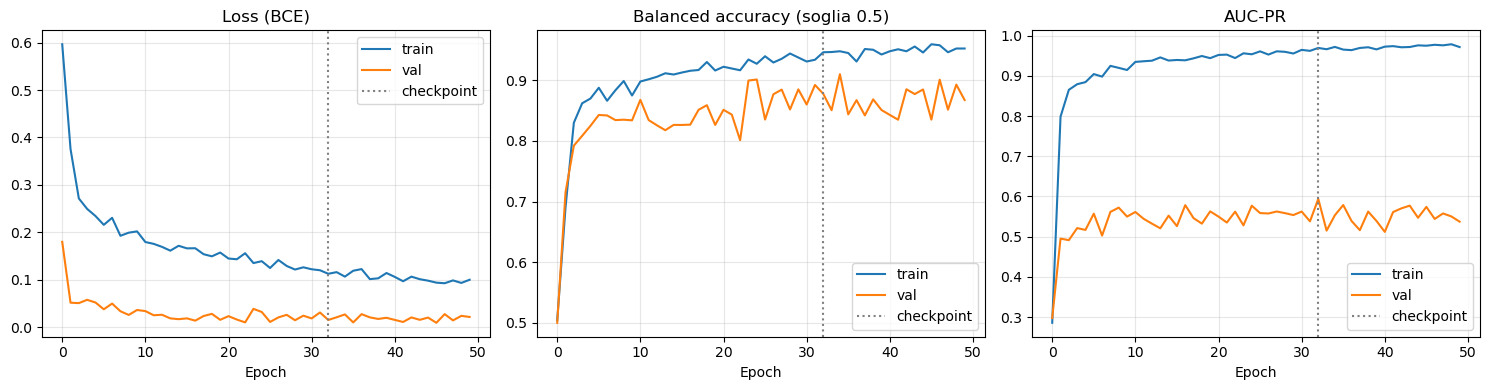

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k, titolo in [(axes[0], "loss", "Loss (BCE)"),
                      (axes[1], "balanced_acc", "Balanced accuracy (soglia 0.5)"),
                      (axes[2], "ap", "AUC-PR")]:
    ax.plot(history[f"train_{k}"], label="train")
    ax.plot(history[f"val_{k}"],   label="val")
    ax.axvline(best_epoch - 1, color="gray", ls=":", label="checkpoint")
    ax.set_title(titolo)
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(MODEL_OUT.with_suffix(".curves.png"), dpi=120)
plt.show()

## 9 · Caricamento del checkpoint e scelta della soglia sul validation
Qui si sceglie la soglia di probabilità oltre la quale si decide se c'è un fulmine o meno nella finestra.
Si sceglie la soglia per cui F1 è massimo.

In [11]:
ckpt = torch.load(MODEL_OUT, map_location=DEVICE)
model.load_state_dict(ckpt["state_dict"])
model.eval()
print(f"Checkpoint dell'epoca {ckpt['epoch']}  (val AUC-PR {ckpt['val_ap']:.4f})")

@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    p, l = [], []
    for Xb, yb in loader:
        p.append(torch.sigmoid(model(Xb.to(DEVICE))).cpu())
        l.append(yb)
    return torch.cat(p).numpy(), torch.cat(l).numpy()

p_val, l_val = predict_proba(model, val_loader)
prec, rec, thr = precision_recall_curve(l_val, p_val)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_i = int(np.argmax(f1s))
best_threshold = float(thr[best_i])
print(f"Soglia scelta sul validation (max F1): {best_threshold:.4f}")
print(f"  precision = {prec[best_i]:.3f}   recall = {rec[best_i]:.3f}   F1 = {f1s[best_i]:.3f}")

print("\nProbabilità sui positivi del validation : "
      f"mediana={np.median(p_val[l_val == 1]):.4f}  max={p_val[l_val == 1].max():.4f}")
print("Probabilità sui negativi del validation : "
      f"mediana={np.median(p_val[l_val == 0]):.4f}  max={p_val[l_val == 0].max():.4f}")

Checkpoint dell'epoca 33  (val AUC-PR 0.5939)
Soglia scelta sul validation (max F1): 0.9474
  precision = 0.711   recall = 0.552   F1 = 0.621

Probabilità sui positivi del validation : mediana=0.9554  max=1.0000
Probabilità sui negativi del validation : mediana=0.0016  max=0.9898


## 10 · Valutazione finale sul test set
Si guarda con il checkpoint e la soglia scelti sul validation.

Prima le metriche classiche, calcolate solo sulle finestre con etichetta affidabile (test pulito): positive visibili contro negative sicure e quiete. Ambigue e positive deboli si valutano a parte nelle misure 2 e 3.

Test 'pulito' (positive visibili vs negative sicure/quiete)
              precision    recall  f1-score   support

  No fulmine      1.000     1.000     1.000   1529743
     Fulmine      0.180     0.612     0.278       116

    accuracy                          1.000   1529859
   macro avg      0.590     0.806     0.639   1529859
weighted avg      1.000     1.000     1.000   1529859

AUC-ROC : 0.9827
AUC-PR  : 0.4406   (casuale = 0.00008)


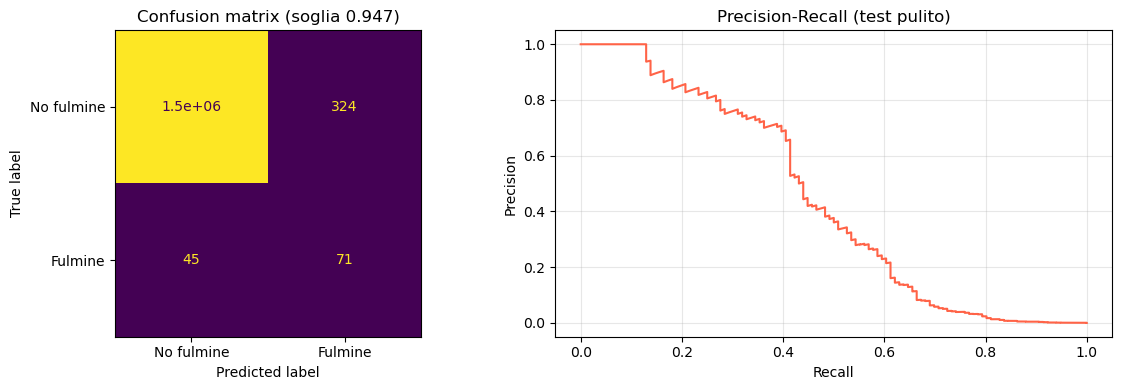

In [12]:
p_test, _ = predict_proba(model, test_loader)
det = p_test >= best_threshold                        # rilevamenti della rete
pulito = np.isin(g_test, [0, 1, 4])
l_cl, p_cl, d_cl = (g_test[pulito] == 1).astype(int), p_test[pulito], det[pulito].astype(int)

print("=" * 60)
print("Test 'pulito' (positive visibili vs negative sicure/quiete)")
print(classification_report(l_cl, d_cl, target_names=["No fulmine", "Fulmine"], digits=3))
print(f"AUC-ROC : {roc_auc_score(l_cl, p_cl):.4f}")
print(f"AUC-PR  : {average_precision_score(l_cl, p_cl):.4f}   (casuale = {l_cl.mean():.5f})")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay(confusion_matrix(l_cl, d_cl),
                       display_labels=["No fulmine", "Fulmine"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix (soglia {best_threshold:.3f})")
pr, rc, _ = precision_recall_curve(l_cl, p_cl)
axes[1].plot(rc, pr, color="tomato")
axes[1].set_title("Precision-Recall (test pulito)"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(MODEL_OUT.with_suffix(".metrics.png"), dpi=120); plt.show()

Nel grafico, muovendosi verso destra di abbassa la soglia, quindi la decisione 'è un fulmine' è più permissiva

### Rete contro baseline, oglia in base ai falsi allarmi
1. Soglia scelta in base ai falsi allarmi accettabili
2. Confronto con la baseline: la stessa valutazione fatta usando solo il criterio della pipeline (SNR o salto massimo, `score_test`). Se la rete non fa meglio della baseline a parità di falsi allarmi, non ha imparato niente oltre all'ampiezza del segnale.

Dati in giorni senza fulmini: 90.0 giorni   |   positive visibili nel test: 116

AUC-PR test pulito   rete: 0.4406   baseline: 0.2633   (casuale = 0.00008)

  falsi allarmi/giorno | recall rete | recall baseline
                 ≤ 0.1 |       0.267 |           0.198
                 ≤ 0.3 |       0.414 |           0.250
                   ≤ 1 |       0.500 |           0.353
                   ≤ 3 |       0.612 |           0.440
                  ≤ 10 |       0.690 |           0.491

Punto di lavoro con FA_TARGET = 1.0/giorno:
  rete     : soglia 0.9810  → 0.87 falsi allarmi/giorno, recall 0.500
  baseline : soglia 13.882  → 0.94 falsi allarmi/giorno, recall 0.353


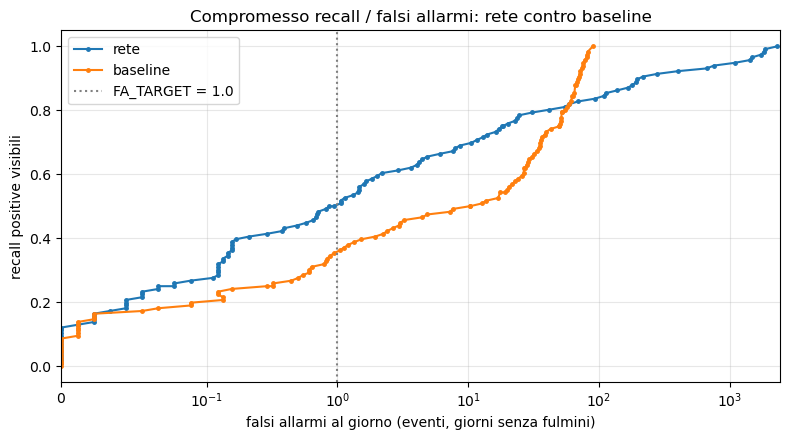

In [13]:
GAP_EVENTO_S = 10      # rilevamenti più vicini di così = stesso evento
FA_TARGET    = 1.0     # falsi allarmi (eventi) al giorno accettati nei giorni senza fulmini

score_base = data["score_test"].astype(np.float64)       # criterio della pipeline (SNR o salto)
t_sec  = t_test.astype("datetime64[s]").astype("int64")
m_free = (g_test == 0) & dayfree_test                       # giorni senza fulmini: ogni evento è un errore
m_vis  = g_test == 1
giorni = m_free.sum() * NEGATIVE_STRIDE / 86400

def n_eventi(mask):
    """Numero di eventi distinti tra le finestre selezionate (raggruppa entro GAP_EVENTO_S)."""
    ts = np.sort(t_sec[mask])
    return 0 if len(ts) == 0 else int(1 + (np.diff(ts) > GAP_EVENTO_S).sum())

def curva(score, n=120):
    """Per una serie di soglie: (soglia, falsi allarmi/giorno a eventi, recall positive visibili)."""
    soglie = np.unique(np.quantile(score[m_vis], np.linspace(0, 1, n)))
    soglie = np.append(soglie, np.nextafter(score.max(), np.inf))[::-1]   # ultima: nessun rilevamento
    fa  = np.array([n_eventi(m_free & (score >= s)) / giorni for s in soglie])
    rec = np.array([(score[m_vis] >= s).mean() for s in soglie])
    return soglie, fa, rec

def soglia_per_fa(soglie, fa, rec, target):
    """Soglia con il recall più alto tra quelle con falsi allarmi <= target."""
    ok = fa <= target
    if not ok.any():
        return soglie[0], fa[0], rec[0]
    i = np.where(ok)[0][np.argmax(rec[ok])]
    return soglie[i], fa[i], rec[i]

curve = {"rete": curva(p_test), "baseline": curva(score_base)}

print(f"Dati in giorni senza fulmini: {giorni:.1f} giorni   |   positive visibili nel test: {m_vis.sum()}\n")
print(f"AUC-PR test pulito   rete: {average_precision_score(l_cl, p_cl):.4f}   "
      f"baseline: {average_precision_score(l_cl, score_base[pulito]):.4f}   (casuale = {l_cl.mean():.5f})\n")

print(f"{'falsi allarmi/giorno':>22s} | {'recall rete':>11s} | {'recall baseline':>15s}")
for target in [0.1, 0.3, 1, 3, 10]:
    r_n = soglia_per_fa(*curve["rete"], target)[2]
    r_b = soglia_per_fa(*curve["baseline"], target)[2]
    print(f"{'≤ ' + str(target):>22s} | {r_n:11.3f} | {r_b:15.3f}")

# Soglie di lavoro alla stessa quantità di falsi allarmi
thr_net,  fa_net,  rec_net  = soglia_per_fa(*curve["rete"],     FA_TARGET)
thr_base, fa_base, rec_base = soglia_per_fa(*curve["baseline"], FA_TARGET)
det      = p_test     >= thr_net        # da qui in poi i rilevamenti usano questa soglia
det_base = score_base >= thr_base
print(f"\nPunto di lavoro con FA_TARGET = {FA_TARGET}/giorno:")
print(f"  rete     : soglia {thr_net:.4f}  → {fa_net:.2f} falsi allarmi/giorno, recall {rec_net:.3f}")
print(f"  baseline : soglia {thr_base:.3f}  → {fa_base:.2f} falsi allarmi/giorno, recall {rec_base:.3f}")
for nome, r in [("rete", rec_net), ("baseline", rec_base)]:
    if r == 0:
        print(f"  ⚠️ {nome}: nessuna soglia trova fulmini restando sotto {FA_TARGET} falsi allarmi/giorno")

fig, ax = plt.subplots(figsize=(8, 4.5))
for nome, (s, fa, rec) in curve.items():
    ax.plot(fa, rec, "o-", ms=2.5, label=nome)
ax.axvline(FA_TARGET, color="gray", ls=":", label=f"FA_TARGET = {FA_TARGET}")
ax.set_xscale("symlog", linthresh=0.1); ax.set_xlim(left=0)
ax.set_xlabel("falsi allarmi al giorno (eventi, giorni senza fulmini)")
ax.set_ylabel("recall positive visibili")
ax.set_title("Compromesso recall / falsi allarmi: rete contro baseline")
ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout(); plt.show()

### Misura 2 · Recall sui fulmini di catalogo
Alla soglia scelta sopra. Le positive deboli non ci si aspetta di trovarle: il dato è solo informativo.

In [14]:
for k in [1, 3]:
    m = g_test == k
    if m.any():
        print(f"{NOMI_CAT[k]:<14s}: rete {det[m].sum():>5} su {m.sum():>5} (recall {det[m].mean():.3f})"
              f"   |   baseline {det_base[m].sum():>5} (recall {det_base[m].mean():.3f})")

pos. visibile : rete    58 su   116 (recall 0.500)   |   baseline    41 (recall 0.353)
pos. debole   : rete     8 su   844 (recall 0.009)   |   baseline     0 (recall 0.000)


### Misura 3 · I rilevamenti extra si concentrano attorno ai temporali? (per evento)
Eventi rilevati per ora di dati, sulle finestre senza fulmine in catalogo, in funzione della distanza dal fulmine più vicino. Rete e baseline sono confrontate alla stessa quantità di falsi allarmi nei giorni senza fulmini.

Se il rapporto "vicino ai temporali / giorni senza fulmini" è più alto per la rete, la rete distingue meglio della baseline gli eventi legati ai temporali dal rumore.

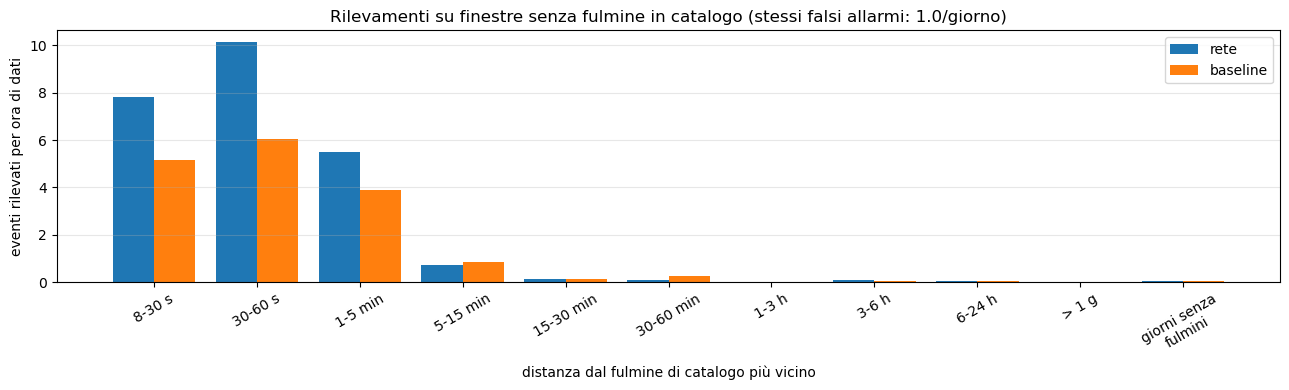

            | rete /ora  × rif. | baseline /ora  × rif. | finestre
     8-30 s |     7.803   215.1 |         5.162   132.1 | 4284
    30-60 s |    10.130   279.2 |         6.023   154.1 | 3757
    1-5 min |     5.504   151.7 |         3.900    99.8 | 11867
   5-15 min |     0.722    19.9 |         0.857    21.9 | 11402
  15-30 min |     0.140     3.9 |         0.140     3.6 | 11044
  30-60 min |     0.089     2.5 |         0.237     6.1 | 17347
      1-3 h |     0.020     0.5 |         0.000     0.0 | 52619
      3-6 h |     0.071     2.0 |         0.024     0.6 | 65293
     6-24 h |     0.031     0.9 |         0.041     1.1 | 99614
      > 1 g |       nan     nan |           nan     nan | 0
giorni senza fulmini |     0.036     1.0 |         0.039     1.0 | 1289893

Eventi ambigui rilevati: rete 297, baseline 219  (finestre ambigue: 37377)


In [15]:
neg_all  = np.isin(g_test, [0, 2, 4])
edges    = np.array([8, 30, 60, 300, 900, 1800, 3600, 3*3600, 6*3600, 24*3600, np.inf])
b_idx    = np.digitize(np.abs(dt_test), edges) - 1
labels_b = ["8-30 s", "30-60 s", "1-5 min", "5-15 min", "15-30 min", "30-60 min",
            "1-3 h", "3-6 h", "6-24 h", "> 1 g"]
gruppi = [neg_all & ~dayfree_test & (b_idx == k) for k in range(len(labels_b))] + [neg_all & dayfree_test]
nomi_g = labels_b + ["giorni senza\nfulmini"]

def tassi(d):
    return np.array([n_eventi(g & d) / (g.sum() * NEGATIVE_STRIDE / 3600) if g.any() else np.nan
                     for g in gruppi])

r_net, r_base = tassi(det), tassi(det_base)
x = np.arange(len(gruppi))
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(x - 0.2, r_net,  0.4, label="rete")
ax.bar(x + 0.2, r_base, 0.4, label="baseline")
ax.set_xticks(x, nomi_g, rotation=30)
ax.set_ylabel("eventi rilevati per ora di dati")
ax.set_xlabel("distanza dal fulmine di catalogo più vicino")
ax.set_title(f"Rilevamenti su finestre senza fulmine in catalogo (stessi falsi allarmi: {FA_TARGET}/giorno)")
ax.grid(alpha=0.3, axis="y"); ax.legend()
plt.tight_layout(); plt.show()

print(f"{'':>11s} | {'rete /ora':>9s} {'× rif.':>7s} | {'baseline /ora':>13s} {'× rif.':>7s} | finestre")
for nome, a, b, g in zip(nomi_g, r_net, r_base, gruppi):
    print(f"{nome.replace(chr(10), ' '):>11s} | {a:9.3f} {a / r_net[-1]:7.1f} | {b:13.3f} {b / r_base[-1]:7.1f} | {g.sum()}")
print(f"\nEventi ambigui rilevati: rete {n_eventi((g_test == 2) & det)}, baseline {n_eventi((g_test == 2) & det_base)}"
      f"  (finestre ambigue: {(g_test == 2).sum()})")

Dove x rif. è il rapporto di trasso di rilevamento di fulmini ambigui nell'intervallo dato e il tasso di rilevamento di fulmini ambigui nei momenti molto lontani da altri fulmini.

#### Controllo a occhio: le finestre ambigue con probabilità più alta
Le 8 finestre ambigue a cui la rete dà la probabilità più alta, accanto a 4 positive visibili per confronto.

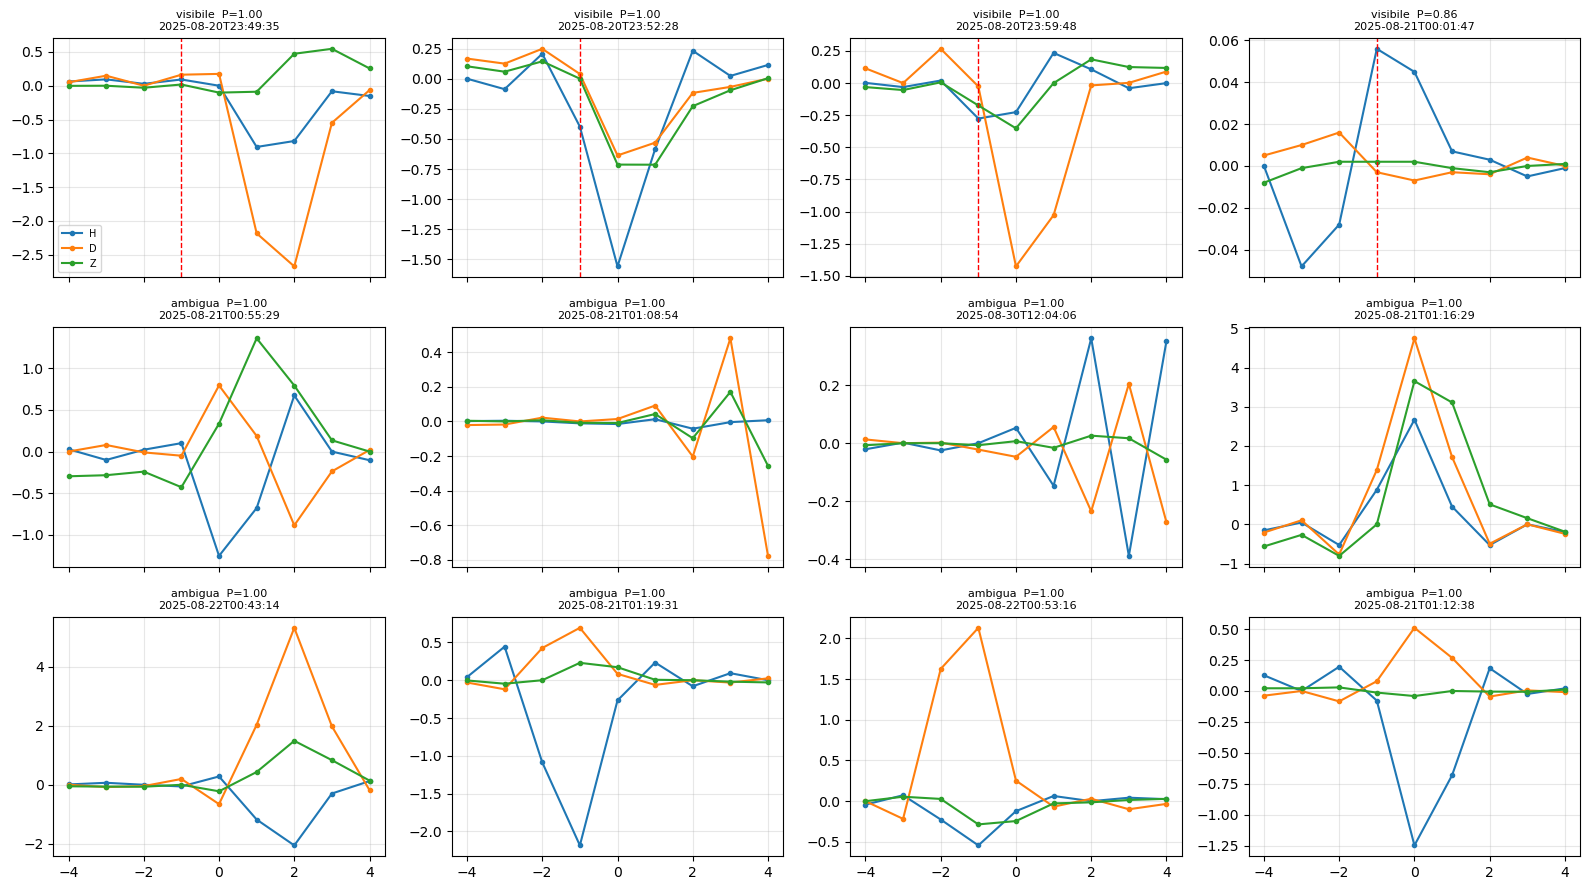

In [16]:
amb = np.where(g_test == 2)[0]
top_amb = amb[np.argsort(p_test[amb])[::-1][:8]]
ex_pos = np.where(g_test == 1)[0][:4]
T_len = X_test.shape[1]; hw = T_len // 2
t_axis = np.arange(-hw, hw + 1)
fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True)
for ax, idx, tipo in [(a, i, "visibile") for a, i in zip(axes[0], ex_pos)] + \
                     [(a, i, "ambigua") for a, i in zip(axes[1:].ravel(), top_amb)]:
    w = X_test[idx] - np.median(X_test[idx], axis=0)
    for comp, nome in enumerate(["H", "D", "Z"]):
        ax.plot(t_axis, w[:, comp], "o-", ms=3, label=nome)
    if tipo == "visibile":
        ax.axvline(-CENTER_OFFSET, color="red", ls="--", lw=1)
    ax.set_title(f"{tipo}  P={p_test[idx]:.2f}\n{str(t_test[idx])[:19]}", fontsize=8)
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 11 · Inferenza su una nuova finestra
Applica a una finestra grezza tutto il processo. Così andranno trattati i nuovi dati.

In [17]:
def predict_window(window, model, norm, threshold, noise_local=None, device=DEVICE):
    """
    window      : np.ndarray (T, 3) — finestra grezza in nT
    norm        : contenuto di .norm.npz
    threshold   : soglia di decisione
    noise_local : rumore dei 5 minuti precedenti (serve solo con "rumore_locale")
    Restituisce (probabilità, 1=fulmine / 0=no fulmine)
    """
    x = window - np.median(window, axis=0, keepdims=True)
    if str(norm["mode"]) == "rumore_locale":
        n = max(float(np.nan_to_num(noise_local, nan=norm["noise_floor"])), float(norm["noise_floor"]))
        x = np.arcsinh(x / n).astype(np.float32)
    else:
        x = np.arcsinh(x / norm["scale"].squeeze()).astype(np.float32)
    x = torch.tensor(x).permute(1, 0).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(model(x)).item()
    return prob, int(prob >= threshold)


norm = np.load(MODEL_OUT.with_suffix(".norm.npz"))
first_pos = np.where(g_test == 1)[0][0]
prob, label = predict_window(X_test[first_pos], model, norm, thr_net,
                             noise_local=None if noise_test is None else noise_test[first_pos])
print(f"Finestra #{first_pos} → P(fulmine) = {prob:.3f} → {'FULMINE' if label else 'no fulmine'}")

Finestra #0 → P(fulmine) = 0.998 → FULMINE


## 12 · Quanto è solido il vantaggio della rete sulla baseline?
Le positive visibili del test sono poche (circa un centinaio), quindi una differenza di qualche punto di recall potrebbe essere dovuta al caso. Due verifiche indipendenti:

**12a · Bootstrap e test di McNemar**.
- Si ricampionano con reinserimento le positive del test migliaia di volte e si ricalcola la differenza rete − baseline: l'intervallo che contiene il 95% dei valori è l'**intervallo di confidenza**. Se non contiene lo 0, il vantaggio è statisticamente solido.
- **McNemar** guarda solo i fulmini su cui i due metodi non sono d'accordo (trovato da uno solo dei due) e dice quanto è probabile uno squilibrio così per puro caso (p < 0.05 → difficilmente è un caso).

**12b · Più addestramenti con seed diversi** (lento: `N_SEEDS` addestramenti completi).
Ogni addestramento parte da pesi casuali diversi e dà risultati un po' diversi. Si riporta media ± deviazione standard: se la rete batte la baseline in tutti i casi, il risultato non dipende dalla fortuna di un singolo addestramento.

Positive visibili nel test: 116   (bootstrap: 2000 ricampionamenti)

Δ AUC-PR (rete − baseline)      : +0.177   IC 95% [+0.116, +0.238]   → solido ✔
Δ recall a 1.0 falsi all./giorno: +0.147   IC 95% [+0.060, +0.233]   → solido ✔

McNemar: fulmini trovati solo dalla rete = 23, solo dalla baseline = 6  → p = 0.0023


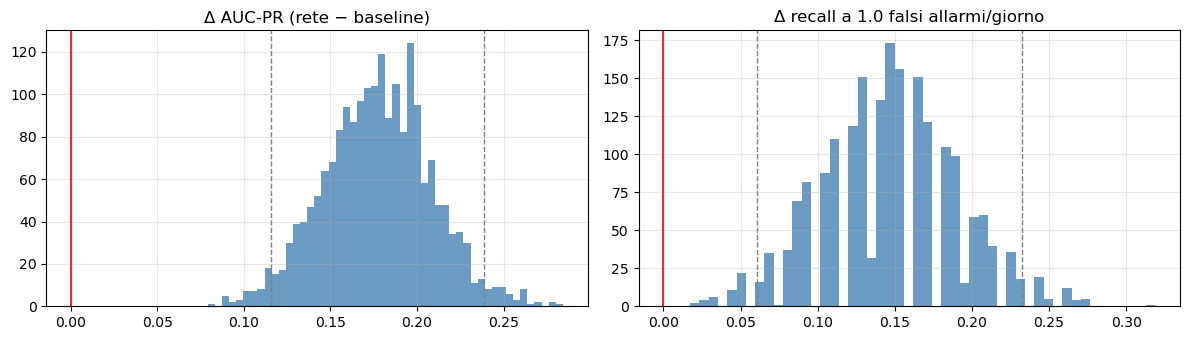

In [18]:
from scipy.stats import binomtest

N_BOOT = 2000
rng_b = np.random.default_rng(0)

# Negative del test pulito (fisse) e positive visibili (ricampionate)
neg_cl = pulito & (g_test != 1)
pos_idx = np.where(m_vis)[0]

def prep_ap(score):
    """Per ogni positiva: quante negative hanno punteggio >= del suo."""
    sn = np.sort(score[neg_cl])
    sp = score[pos_idx]
    return sp, len(sn) - np.searchsorted(sn, sp, side="left")

def ap_campione(sp, n_neg_sopra, ii):
    """Average precision calcolata sulle positive ii (negative fisse)."""
    s = sp[ii]
    ordine = np.sort(s)
    n_pos_sopra = len(s) - np.searchsorted(ordine, s, side="left")
    return np.mean(n_pos_sopra / (n_pos_sopra + n_neg_sopra[ii]))

sp_n, nn_n = prep_ap(p_test)
sp_b, nn_b = prep_ap(score_base)
hit_n = p_test[pos_idx] >= thr_net          # trovato dalla rete (a FA_TARGET)
hit_b = score_base[pos_idx] >= thr_base     # trovato dalla baseline (a FA_TARGET)

d_ap, d_rec = [], []
for _ in range(N_BOOT):
    ii = rng_b.integers(0, len(pos_idx), len(pos_idx))
    d_ap.append(ap_campione(sp_n, nn_n, ii) - ap_campione(sp_b, nn_b, ii))
    d_rec.append(hit_n[ii].mean() - hit_b[ii].mean())
d_ap, d_rec = np.array(d_ap), np.array(d_rec)

def riga(nome, valore, campioni):
    lo, hi = np.percentile(campioni, [2.5, 97.5])
    esito = "solido ✔" if lo > 0 else ("a favore della baseline" if hi < 0 else "non conclusivo")
    print(f"{nome:<32s}: {valore:+.3f}   IC 95% [{lo:+.3f}, {hi:+.3f}]   → {esito}")

print(f"Positive visibili nel test: {len(pos_idx)}   (bootstrap: {N_BOOT} ricampionamenti)\n")
riga("Δ AUC-PR (rete − baseline)", ap_campione(sp_n, nn_n, np.arange(len(pos_idx)))
     - ap_campione(sp_b, nn_b, np.arange(len(pos_idx))), d_ap)
riga(f"Δ recall a {FA_TARGET} falsi all./giorno", hit_n.mean() - hit_b.mean(), d_rec)

solo_rete, solo_base = int((hit_n & ~hit_b).sum()), int((~hit_n & hit_b).sum())
p_mcn = binomtest(solo_rete, solo_rete + solo_base, 0.5).pvalue if solo_rete + solo_base else 1.0
print(f"\nMcNemar: fulmini trovati solo dalla rete = {solo_rete}, solo dalla baseline = {solo_base}"
      f"  → p = {p_mcn:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, camp, titolo in [(axes[0], d_ap, "Δ AUC-PR (rete − baseline)"),
                         (axes[1], d_rec, f"Δ recall a {FA_TARGET} falsi allarmi/giorno")]:
    ax.hist(camp, bins=50, color="steelblue", alpha=0.8)
    ax.axvline(0, color="red", lw=1.2)
    for q in np.percentile(camp, [2.5, 97.5]):
        ax.axvline(q, color="gray", ls="--", lw=1)
    ax.set_title(titolo); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Sulle ascisse c'è la differenza dei risultati rete-baseline, sulle ordinate il numero dei risultati del bootstrap che ha ottenuto quel risultato. Le linee grigie delimitano l'interfallo di confidenza 2 sigma, la linea rossa invece il valore 0. Il grafico a destra è a pettine perché il recall è una statistica disccreta.

In [19]:
# Più addestramenti con seed diversi
N_SEEDS = 5          # ogni seed = un addestramento completo. 0 per saltare.
import copy

def addestra(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    m = LightningCNN(in_channels=3).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=7)
    best, best_state = -1.0, None
    for ep in range(EPOCHS):
        run_epoch(m, train_loader, criterion, opt)
        va = run_epoch(m, val_loader, criterion)
        sch.step(va["ap"])
        if va["ap"] > best:
            best, best_state = va["ap"], copy.deepcopy(m.state_dict())
    m.load_state_dict(best_state)
    return m, best

risultati = []
for seed in range(N_SEEDS):
    m_s, ap_val = addestra(seed)
    p_s, _ = predict_proba(m_s, test_loader)
    thr_s, fa_s, rec_s = soglia_per_fa(*curva(p_s), FA_TARGET)
    ap_s = average_precision_score(l_cl, p_s[pulito])
    risultati.append((seed, ap_val, ap_s, rec_s, fa_s))
    print(f"seed {seed}: val AUC-PR {ap_val:.3f} | test AUC-PR {ap_s:.3f} | "
          f"recall {rec_s:.3f} a {fa_s:.2f} falsi all./giorno")

if risultati:
    r = np.array(risultati)
    ap_base = average_precision_score(l_cl, score_base[pulito])
    print(f"\nRete  ({N_SEEDS} seed): test AUC-PR = {r[:, 2].mean():.3f} ± {r[:, 2].std():.3f}   "
          f"recall = {r[:, 3].mean():.3f} ± {r[:, 3].std():.3f}")
    print(f"Baseline           : test AUC-PR = {ap_base:.3f}             recall = {rec_base:.3f}")
    print(f"La rete batte la baseline in AUC-PR in {(r[:, 2] > ap_base).sum()} seed su {N_SEEDS}, "
          f"in recall in {(r[:, 3] > rec_base).sum()} su {N_SEEDS}")

seed 0: val AUC-PR 0.740 | test AUC-PR 0.469 | recall 0.526 a 0.90 falsi all./giorno
seed 1: val AUC-PR 0.676 | test AUC-PR 0.454 | recall 0.509 a 0.99 falsi all./giorno
seed 2: val AUC-PR 0.738 | test AUC-PR 0.467 | recall 0.552 a 0.96 falsi all./giorno
seed 3: val AUC-PR 0.657 | test AUC-PR 0.479 | recall 0.543 a 0.99 falsi all./giorno
seed 4: val AUC-PR 0.711 | test AUC-PR 0.441 | recall 0.517 a 0.99 falsi all./giorno

Rete  (5 seed): test AUC-PR = 0.462 ± 0.013   recall = 0.529 ± 0.016
Baseline           : test AUC-PR = 0.263             recall = 0.353
La rete batte la baseline in AUC-PR in 5 seed su 5, in recall in 5 su 5
